# Tecnológico de Monterrey
## Proyecto Integrador — Equipo 23
## Avance 5. Modelo final

**Integrantes:** Edmundo Carmona Galindo (A01796647) · Jaqueline Villafranca Hernández (A01656679) · Edgar Omar Cruz Mendoza (A01795590)

---

### Problema

Cotejo entre fichas de búsqueda de personas desaparecidas (ante-mortem) y expedientes del registro forense
(post-mortem). Es **vinculación de registros evaluada como ranking**, no clasificación binaria: el modelo puntúa
pares (ficha, expediente) y entrega una lista corta de candidatos; el perito confirma o descarta con evidencia
forense.

El error costoso es el falso negativo: si el expediente correcto no aparece entre los primeros candidatos, el
perito no lo revisa. La métrica principal es por tanto **Recall@10**.

### Datos

Este avance usa un **registro sintético** (`Datos/REGISTRO_SINTETICO_NECROPSIAS.xlsx`, generado por
`Datos/generar_registro_sintetico.py`) con la misma estructura y perfil agregado que el registro del SEMEFO
(1,247 expedientes, 355 identificados), pero con contenido 100 % inventado. Las consultas son pseudo-fichas generadas
con ruido controlado a partir de los expedientes identificados (partición 70/30 por expediente). Las cifras son un
techo optimista y no deben citarse como resultados sobre datos reales.

# Paso 1. Preparación de datos

In [2]:
import re, time, unicodedata
import numpy as np, pandas as pd
from pathlib import Path

SEED = 42
RUTA_EXCEL = Path(r'../Datos/REGISTRO_SINTETICO_NECROPSIAS.xlsx')

df = pd.read_excel(RUTA_EXCEL)
df.columns = df.columns.astype(str).str.strip()

PLACEHOLDERS = {'', 'SIN DATO', 'SIN DATOS', 'NINGUNA', 'NINGUNO', 'NO', 'NA', 'NAN', 'NONE', 'NO PRESENTA',
                'NO SE OBSERVA', 'NO SE OBSERVAN', 'SD', 'S D', 'SIN', 'NO APLICA', 'NO VALORABLE', 'DESCONOCIDO', 'X', '0'}

def norm_txt(x):
    if x is None or (isinstance(x, float) and np.isnan(x)): return ''
    s = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Z0-9 ]', ' ', s.upper())).strip()

def limpiar(x):
    s = norm_txt(x); return '' if s in PLACEHOLDERS else s

def col(*claves):   # busca la columna por palabras clave (los nombres reales traen saltos de línea)
    return next(c for c in df.columns if all(k in norm_txt(c) for k in claves))

def parse_edad(x):
    if pd.isna(x): return np.nan
    s = str(x).upper(); nums = [float(n) for n in re.findall(r'\d+(?:\.\d+)?', s)]
    if not nums: return np.nan
    if 'MES' in s: return nums[0] / 12
    if 'DIA' in s or 'SEMANA' in s: return 0.0
    v = np.mean(nums[:2]) if len(nums) >= 2 and nums[1] < 120 else nums[0]
    return v if 0 <= v <= 110 else np.nan

def parse_estatura(x):
    if pd.isna(x): return np.nan
    nums = re.findall(r'\d+(?:\.\d+)?', str(x))
    if not nums: return np.nan
    v = float(nums[0]); v = v * 100 if v < 3 else v
    return v if 40 <= v <= 220 else np.nan

def parse_sexo(x):
    s = norm_txt(x)
    return 'M' if s.startswith(('MASC', 'HOMBRE')) else 'F' if s.startswith(('FEM', 'MUJER')) else 'ND'

exp = df[df[col('STATUS')].notna() | df[col('ANO')].notna()]        # fuera las filas vacías de formato
tiene_nombre = exp[col('CASO', 'IDENTIFICADO', 'NOMBRE')].map(limpiar).ne('')
bl = pd.DataFrame({
    'ID_INTERNO': exp.index.values,
    'SEXO': exp[col('SEXO')].map(parse_sexo).values,
    'EDAD': exp[col('EDAD')].map(parse_edad).values,
    'ESTATURA': exp[col('ESTATURA')].map(parse_estatura).values,
    'MUNICIPIO': exp[col('MUNICIPIO', 'PROCEDENCIA')].map(limpiar).values,
    'SENAS': exp[col('SENAS', 'PARTICULARES')].map(limpiar).values,
    'ROPA': exp[col('ROPA', 'VESTIA')].map(limpiar).values,
    'IDENTIFICADO': (exp[col('STATUS')].map(norm_txt).str.startswith('IDENTIFICADO') | tiene_nombre).astype(int).values,
})
print(f"Expedientes: {len(bl):,} | identificados: {bl.IDENTIFICADO.sum()}")

Expedientes: 1,247 | identificados: 355


In [3]:
from sklearn.model_selection import train_test_split

RUIDO_MEDIO = dict(sd_edad=5, sd_est=5, p_falta_est=0.4, p_drop=0.5, p_typo=0.05, p_sin_ropa=0.4, p_mun=0.5, p_sexo=0.02)
MUNICIPIOS = bl.loc[bl.MUNICIPIO.ne(''), 'MUNICIPIO'].unique()

def perturbar(txt, p_drop, p_typo, rng):
    toks = txt.split()
    if not toks: return ''
    keep = [t for t in toks if rng.random() > p_drop] or [toks[rng.integers(len(toks))]]
    out = [(t[:i] + chr(rng.integers(65, 91)) + t[i+1:]) if len(t) > 3 and rng.random() < p_typo and (i := rng.integers(len(t))) is not None else t
           for t in keep]
    rng.shuffle(out); return ' '.join(out)

def pseudofichas(src, p=RUIDO_MEDIO, seed=SEED):
    rng, filas = np.random.default_rng(seed), []
    for _, r in src.iterrows():
        sexo = ('F' if r.SEXO == 'M' else 'M') if r.SEXO in ('M', 'F') and rng.random() < p['p_sexo'] else r.SEXO
        edad = r.EDAD + rng.normal(0, p['sd_edad']) if pd.notna(r.EDAD) else np.nan
        est = np.nan if pd.isna(r.ESTATURA) or rng.random() < p['p_falta_est'] else r.ESTATURA + rng.normal(0, p['sd_est'])
        mun = r.MUNICIPIO if rng.random() >= p['p_mun'] else rng.choice(MUNICIPIOS)
        filas.append(dict(QUERY_ID=int(r.ID_INTERNO), ID_VERDADERO=int(r.ID_INTERNO), SEXO=sexo, EDAD=edad, ESTATURA=est,
                          MUNICIPIO=mun, SENAS=perturbar(r.SENAS, p['p_drop'], p['p_typo'], rng),
                          ROPA='' if rng.random() < p['p_sin_ropa'] else perturbar(r.ROPA, p['p_drop'], p['p_typo'], rng)))
    return pd.DataFrame(filas)

ident = bl[bl.IDENTIFICADO == 1]
ids_train, ids_test = train_test_split(ident.ID_INTERNO.values, test_size=0.30, random_state=SEED)
Q_train = pseudofichas(ident[ident.ID_INTERNO.isin(ids_train)], seed=SEED)
Q_test = pseudofichas(ident[ident.ID_INTERNO.isin(ids_test)], seed=SEED + 1)
print(f"Pseudo-fichas -> entrenamiento: {len(Q_train)} | prueba: {len(Q_test)}")

Pseudo-fichas -> entrenamiento: 248 | prueba: 107


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf_senas = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True).fit(bl.SENAS)
tf_ropa = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True).fit(bl.ROPA)
XS, XR = tf_senas.transform(bl.SENAS), tf_ropa.transform(bl.ROPA)
MARCAS = ['TATUA', 'CICATRI', 'LUNAR', 'PERFORA', 'PIERCING', 'MANCHA', 'AMPUTA', 'QUEMAD', 'VERRUG']
marcas = lambda textos: np.array([[int(m in t) for m in MARCAS] for t in textos], float)
M_bl = marcas(bl.SENAS)

def construir_pares(Q):
    sim_s = (tf_senas.transform(Q.SENAS) @ XS.T).toarray()
    sim_r = (tf_ropa.transform(Q.ROPA) @ XR.T).toarray()
    mc = marcas(Q.SENAS) @ M_bl.T
    bloques = []
    for i, q in enumerate(Q.itertuples(index=False)):
        d_edad = np.abs(bl.EDAD.values - q.EDAD) if pd.notna(q.EDAD) else np.full(len(bl), np.nan)
        d_est = np.abs(bl.ESTATURA.values - q.ESTATURA) if pd.notna(q.ESTATURA) else np.full(len(bl), np.nan)
        m = np.isnan(d_edad) | (d_edad <= 15)                                     # blocking por edad (±15 años)
        if q.SEXO != 'ND':
            m &= (bl.SEXO.values == q.SEXO) | (bl.SEXO.values == 'ND')            # blocking por sexo
        k = np.where(m)[0]
        bloques.append(pd.DataFrame({
            'QUERY_ID': q.QUERY_ID, 'ID_CAND': bl.ID_INTERNO.values[k], 'y': (bl.ID_INTERNO.values[k] == q.ID_VERDADERO).astype(int),
            'dif_edad': np.nan_to_num(d_edad[k], nan=20.0), 'falta_edad': np.isnan(d_edad[k]).astype(int),
            'dif_estatura': np.nan_to_num(d_est[k], nan=20.0), 'falta_estatura': np.isnan(d_est[k]).astype(int),
            'municipio_coincide': ((bl.MUNICIPIO.values[k] == q.MUNICIPIO) & (q.MUNICIPIO != '')).astype(int),
            'sim_senas': sim_s[i, k], 'sim_ropa': sim_r[i, k], 'marcas_comunes': mc[i, k],
            'senas_vacia_exp': (bl.SENAS.values[k] == '').astype(int), 'senas_vacia_ficha': int(q.SENAS == '')}))
    return pd.concat(bloques, ignore_index=True)

P_train, P_test = construir_pares(Q_train), construir_pares(Q_test)

# Las 10 características que quedaron tras la selección (Avance 4 y paso 1; se elimina sexo_coincide)
FEATS_SEL = ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'municipio_coincide',
             'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']
X_tr, y_tr, X_te = P_train[FEATS_SEL], P_train['y'].values, P_test[FEATS_SEL]
techo = P_test.groupby('QUERY_ID').y.max().reindex(Q_test.QUERY_ID).fillna(0).mean()
print(f"Pares train/test: {len(P_train):,}/{len(P_test):,} | correctos: {y_tr.sum()}/{P_test.y.sum()} | techo del protocolo: {techo:.3f}")

Pares train/test: 152,883/67,401 | correctos: 244/102 | techo del protocolo: 0.953


 # Paso 2. Modelos individuales de referencia (mejores del Avance 4)

In [5]:
from sklearn.metrics import average_precision_score

def rangos(P, s):
    """Posición del expediente correcto en la lista de cada ficha (1 = primero).
    Empates: criterio pesimista. Si el blocking eliminó al correcto, la posición es infinito (cuenta como fallo)."""
    df = pd.DataFrame({'q': P['QUERY_ID'].values, 'y': P['y'].values, 's': s})
    s_ok = df[df.y == 1].groupby('q').s.first().rename('s_ok')          # score del correcto en cada ficha
    df = df.join(s_ok, on='q')
    por_encima = df[(df.y == 0) & (df.s >= df.s_ok)].groupby('q').size()  # incorrectos con score >= al correcto
    r = 1 + por_encima.reindex(s_ok.index, fill_value=0)
    fichas = P['QUERY_ID'].unique()
    return r.reindex(fichas).astype(float).fillna(np.inf).values

def metricas(P, s):
    r = rangos(P, s)
    return {'Recall@1': np.mean(r <= 1),
            'Recall@10': np.mean(r <= 10),
            'Recall@20': np.mean(r <= 20),
            'MRR': np.mean(np.where(np.isfinite(r), 1 / r, 0)),
            'PR-AUC': average_precision_score(P['y'], s)}

def puntuar(modelo, X):
    """Probabilidad si el modelo la tiene; si no (SVM), su margen. Para ordenar basta con que sea monótono."""
    return modelo.predict_proba(X)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X)

# Prueba rápida: un "modelo" que ordena solo por similitud de señas, sin aprender nada
print("Solo sim_senas ->", {k: round(v, 3) for k, v in metricas(P_test, P_test['sim_senas'].values).items()})

Solo sim_senas -> {'Recall@1': np.float64(0.421), 'Recall@10': np.float64(0.654), 'Recall@20': np.float64(0.701), 'MRR': np.float64(0.496), 'PR-AUC': 0.182}


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

MODELOS_A4 = {
    'Regresión logística': make_pipeline(StandardScaler(),
                                         LogisticRegression(C=0.01, max_iter=3000, random_state=SEED)),
    'SVM lineal': make_pipeline(StandardScaler(),
                                LinearSVC(C=0.1648, class_weight='balanced', loss='hinge', max_iter=5000, random_state=SEED)),
    'MLP': make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(64,), activation='relu', learning_rate_init=0.000844,
                                       alpha=0.000755, batch_size=256, early_stopping=True, max_iter=200, random_state=SEED)),
}

resultados = []
for nombre, modelo in MODELOS_A4.items():
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); s = puntuar(modelo, X_te); t_inf = (time.perf_counter() - t0) / len(Q_test) * 1000
    resultados.append({'Modelo': nombre, **metricas(P_test, s),
                       'Entrenamiento (s)': t_fit, 'Inferencia (ms/ficha)': t_inf})

tabla_ref = pd.DataFrame(resultados).set_index('Modelo').sort_values('Recall@10', ascending=False)
tabla_ref.round(3)

c:\Users\carmo\anaconda3\envs\mna-avance5\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Recall@1,Recall@10,Recall@20,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,
Regresión logística,0.673,0.869,0.888,0.732,0.533,0.133,0.101
MLP,0.701,0.860,0.869,0.753,0.696,20.608,0.469
SVM lineal,0.533,0.822,0.879,0.639,0.339,14.003,0.164


# Paso 3. Ensambles homogéneos

### 3.1 Random Forest (bagging)

In [8]:
from sklearn.model_selection import GroupKFold, ParameterSampler
from sklearn.ensemble import RandomForestClassifier

def cv_recall10(construir, n_splits=3):
    """Examen de práctica: validación cruzada agrupada por ficha, SOLO con datos de entrenamiento."""
    r10, mrr = [], []
    for tr, va in GroupKFold(n_splits=n_splits).split(X_tr, y_tr, groups=P_train['QUERY_ID']):
        m = construir().fit(X_tr.iloc[tr], y_tr[tr])
        met = metricas(P_train.iloc[va], puntuar(m, X_tr.iloc[va]))
        r10.append(met['Recall@10']); mrr.append(met['MRR'])
    return np.mean(r10), np.mean(mrr)

# 2. Referencia: la regresión logística con el MISMO examen de práctica
ref_r10, ref_mrr = cv_recall10(lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=3000, random_state=SEED)))
print(f"Referencia (regresión logística, CV) -> Recall@10 = {ref_r10:.3f} | MRR = {ref_mrr:.3f}\n")

# 3. Configuraciones candidatas: 12 al azar de 1,080 posibles
espacio_rf = {'n_estimators': [100, 200, 300], 'max_depth': [None, 6, 10, 16], 'min_samples_leaf': [1, 5, 20, 50, 100],
              'max_features': ['sqrt', 0.5, 1.0], 'max_samples': [0.3, 0.6, None], 'class_weight': [None, 'balanced_subsample']}
configs = list(ParameterSampler(espacio_rf, n_iter=12, random_state=SEED))

# 4. Calificar cada configuración
busqueda_rf = []
t0 = time.perf_counter()
for i, cfg in enumerate(configs, 1):
    r10, mrr = cv_recall10(lambda: RandomForestClassifier(**cfg, n_jobs=-1, random_state=SEED))
    busqueda_rf.append({'config': i, 'Recall@10 (CV)': r10, 'MRR (CV)': mrr, **cfg})
    print(f"  config {i:>2}/{len(configs)} -> Recall@10 = {r10:.3f} | MRR = {mrr:.3f}")
t_busqueda_rf = time.perf_counter() - t0

busqueda_rf = pd.DataFrame(busqueda_rf).sort_values(['Recall@10 (CV)', 'MRR (CV)'], ascending=False)
mejor_rf = configs[int(busqueda_rf.iloc[0]['config']) - 1]
print(f"\nBúsqueda: {t_busqueda_rf:.0f} s | mejor configuración: {mejor_rf}")

# 5. Modelo final: entrenar con TODO el entrenamiento y evaluar UNA sola vez en prueba
rf = RandomForestClassifier(**mejor_rf, n_jobs=-1, random_state=SEED)
t0 = time.perf_counter(); rf.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); s = puntuar(rf, X_te); t_inf = (time.perf_counter() - t0) / len(Q_test) * 1000
tabla_ref.loc['Random Forest'] = {**metricas(P_test, s), 'Entrenamiento (s)': t_fit, 'Inferencia (ms/ficha)': t_inf}
tabla_ref.sort_values('Recall@10', ascending=False).round(3)

Referencia (regresión logística, CV) -> Recall@10 = 0.911 | MRR = 0.813

  config  1/12 -> Recall@10 = 0.871 | MRR = 0.783
  config  2/12 -> Recall@10 = 0.891 | MRR = 0.765
  config  3/12 -> Recall@10 = 0.903 | MRR = 0.751
  config  4/12 -> Recall@10 = 0.851 | MRR = 0.755
  config  5/12 -> Recall@10 = 0.782 | MRR = 0.693
  config  6/12 -> Recall@10 = 0.766 | MRR = 0.694
  config  7/12 -> Recall@10 = 0.782 | MRR = 0.726
  config  8/12 -> Recall@10 = 0.851 | MRR = 0.755
  config  9/12 -> Recall@10 = 0.843 | MRR = 0.677
  config 10/12 -> Recall@10 = 0.867 | MRR = 0.690
  config 11/12 -> Recall@10 = 0.875 | MRR = 0.688
  config 12/12 -> Recall@10 = 0.883 | MRR = 0.754

Búsqueda: 88 s | mejor configuración: {'n_estimators': 300, 'min_samples_leaf': 50, 'max_samples': 0.3, 'max_features': 0.5, 'max_depth': 6, 'class_weight': 'balanced_subsample'}


,Recall@1,Recall@10,Recall@20,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,
Regresión logística,0.673,0.869,0.888,0.732,0.533,0.133,0.101
MLP,0.701,0.860,0.869,0.753,0.696,20.608,0.469
Random Forest,0.607,0.850,0.869,0.687,0.571,4.641,1.695
SVM lineal,0.533,0.822,0.879,0.639,0.339,14.003,0.164


### 3.2 Gradient Boosting (boosting)

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier

espacio_hgb = {'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2], 'max_iter': [100, 200, 400],
               'max_leaf_nodes': [7, 15, 31, 63], 'min_samples_leaf': [20, 50, 100, 200],
               'l2_regularization': [0.0, 0.01, 0.1, 1.0, 10.0], 'class_weight': [None, 'balanced']}
configs_hgb = list(ParameterSampler(espacio_hgb, n_iter=12, random_state=SEED))

busqueda_hgb = []
t0 = time.perf_counter()
for i, cfg in enumerate(configs_hgb, 1):
    # early_stopping=False: el número de árboles lo fija max_iter, así el resultado es reproducible
    r10, mrr = cv_recall10(lambda: HistGradientBoostingClassifier(**cfg, early_stopping=False, random_state=SEED))
    busqueda_hgb.append({'config': i, 'Recall@10 (CV)': r10, 'MRR (CV)': mrr, **cfg})
    print(f"  config {i:>2}/{len(configs_hgb)} -> Recall@10 = {r10:.3f} | MRR = {mrr:.3f}")
t_busqueda_hgb = time.perf_counter() - t0

busqueda_hgb = pd.DataFrame(busqueda_hgb).sort_values(['Recall@10 (CV)', 'MRR (CV)'], ascending=False)
mejor_hgb = configs_hgb[int(busqueda_hgb.iloc[0]['config']) - 1]
print(f"\nReferencia logística (CV): Recall@10 = {ref_r10:.3f} | Búsqueda: {t_busqueda_hgb:.0f} s")
print(f"Mejor configuración: {mejor_hgb} -> Recall@10 (CV) = {busqueda_hgb.iloc[0]['Recall@10 (CV)']:.3f}")

hgb = HistGradientBoostingClassifier(**mejor_hgb, early_stopping=False, random_state=SEED)
t0 = time.perf_counter(); hgb.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); s = puntuar(hgb, X_te); t_inf = (time.perf_counter() - t0) / len(Q_test) * 1000
tabla_ref.loc['Gradient Boosting'] = {**metricas(P_test, s), 'Entrenamiento (s)': t_fit, 'Inferencia (ms/ficha)': t_inf}
tabla_ref.sort_values('Recall@10', ascending=False).round(3)

  config  1/12 -> Recall@10 = 0.826 | MRR = 0.691
  config  2/12 -> Recall@10 = 0.818 | MRR = 0.731
  config  3/12 -> Recall@10 = 0.871 | MRR = 0.748
  config  4/12 -> Recall@10 = 0.875 | MRR = 0.757
  config  5/12 -> Recall@10 = 0.823 | MRR = 0.719
  config  6/12 -> Recall@10 = 0.786 | MRR = 0.431
  config  7/12 -> Recall@10 = 0.617 | MRR = 0.464
  config  8/12 -> Recall@10 = 0.855 | MRR = 0.620
  config  9/12 -> Recall@10 = 0.843 | MRR = 0.709
  config 10/12 -> Recall@10 = 0.863 | MRR = 0.666
  config 11/12 -> Recall@10 = 0.831 | MRR = 0.687
  config 12/12 -> Recall@10 = 0.863 | MRR = 0.726

Referencia logística (CV): Recall@10 = 0.911 | Búsqueda: 90 s
Mejor configuración: {'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 10.0, 'class_weight': None} -> Recall@10 (CV) = 0.875


,Recall@1,Recall@10,Recall@20,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,
Regresión logística,0.673,0.869,0.888,0.732,0.533,0.133,0.101
MLP,0.701,0.860,0.869,0.753,0.696,20.608,0.469
Random Forest,0.607,0.850,0.869,0.687,0.571,4.641,1.695
Gradient Boosting,0.673,0.841,0.869,0.723,0.676,2.957,3.552
SVM lineal,0.533,0.822,0.879,0.639,0.339,14.003,0.164


Hasta ahora el modelo de regresión logistica ha sido el mejor esto confirma que los dos ensambles homogéneos dicen lo mismo: más flexibilidad sobre las mismas pistas no mejora el resultado.

## Paso 4: ensambles heterogéneos

In [10]:
from sklearn.base import clone

BASES = {'logistica': MODELOS_A4['Regresión logística'], 'svm': MODELOS_A4['SVM lineal'], 'mlp': MODELOS_A4['MLP']}
pliegues = list(GroupKFold(n_splits=3).split(X_tr, y_tr, groups=P_train['QUERY_ID']))

# Predicciones fuera de pliegue: cada par de entrenamiento lo puntúa un modelo que NO vio su ficha
oof = pd.DataFrame(index=P_train.index, columns=list(BASES), dtype=float)
t0 = time.perf_counter()
for nombre, modelo in BASES.items():
    for tr, va in pliegues:
        m = clone(modelo).fit(X_tr.iloc[tr], y_tr[tr])            # clone = copia sin entrenar
        oof.iloc[va, oof.columns.get_loc(nombre)] = puntuar(m, X_tr.iloc[va])
    print(f"  {nombre:<10} listo")
t_oof = time.perf_counter() - t0
print(f"Predicciones OOF en {t_oof:.0f} s\n")

# Scores en PRUEBA de los modelos base (ya entrenados en la celda 3 con todo el entrenamiento)
S_test = pd.DataFrame({n: puntuar(m, X_te) for n, m in BASES.items()}, index=P_test.index)

# ¿Se equivocan en fichas distintas? (calculado con las OOF, sin tocar la prueba)
acierta = pd.DataFrame({n: rangos(P_train, oof[n].values) <= 10 for n in BASES})
print("Recall@10 OOF de cada modelo:", acierta.mean().round(3).to_dict())
print(f"Oráculo (al menos uno acierta): {acierta.any(axis=1).mean():.3f} | los tres aciertan: {acierta.all(axis=1).mean():.3f}")
print("\nFichas de entrenamiento según acierte (True) o no (False) cada modelo:")
pd.crosstab(acierta['logistica'], acierta['mlp'], rownames=['Logística acierta'], colnames=['MLP acierta'])

  logistica  listo


c:\Users\carmo\anaconda3\envs\mna-avance5\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\carmo\anaconda3\envs\mna-avance5\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\carmo\anaconda3\envs\mna-avance5\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  svm        listo
  mlp        listo
Predicciones OOF en 17 s

Recall@10 OOF de cada modelo: {'logistica': 0.911, 'svm': 0.887, 'mlp': 0.907}
Oráculo (al menos uno acierta): 0.919 | los tres aciertan: 0.875

Fichas de entrenamiento según acierte (True) o no (False) cada modelo:


MLP acierta,False,True
Logística acierta,,
False,21,1
True,2,224


### 4.1 Votación ponderada

In [11]:
def normalizar_por_ficha(P, S):
    """z-score de cada modelo dentro de cada ficha: pone los tres scores en la misma escala."""
    g = S.groupby(P['QUERY_ID'].values)
    return (S - g.transform('mean')) / g.transform('std').replace(0, 1)

Z_oof = normalizar_por_ficha(P_train, oof)

# Búsqueda de pesos sobre las predicciones fuera de pliegue (nunca sobre la prueba)
pesos = [(a / 10, b / 10, (10 - a - b) / 10) for a in range(11) for b in range(11 - a)
         if sum(x > 0 for x in (a, b, 10 - a - b)) >= 2]          # al menos dos modelos: si no, no es ensamble
t0 = time.perf_counter()
filas = []
for w in pesos:
    met = metricas(P_train, Z_oof.values @ np.array(w))
    filas.append({'w_logistica': w[0], 'w_svm': w[1], 'w_mlp': w[2],
                  'Recall@10 (OOF)': met['Recall@10'], 'MRR (OOF)': met['MRR'], 'Recall@1 (OOF)': met['Recall@1']})
t_busqueda_voto = time.perf_counter() - t0
busqueda_voto = pd.DataFrame(filas).sort_values(['Recall@10 (OOF)', 'MRR (OOF)'], ascending=False)
print(f"{len(pesos)} combinaciones de pesos en {t_busqueda_voto:.0f} s. Las 5 mejores:")
display(busqueda_voto.head(5).round(3))
w_voto = busqueda_voto.iloc[0][['w_logistica', 'w_svm', 'w_mlp']].values.astype(float)
print(f"Pesos elegidos -> logística {w_voto[0]:.1f} | SVM {w_voto[1]:.1f} | MLP {w_voto[2]:.1f}")

# Evaluación UNA vez en prueba. Costo = entrenar los 3 modelos base + buscar pesos; inferencia = 3 modelos + normalizar
t0 = time.perf_counter(); s = normalizar_por_ficha(P_test, S_test).values @ w_voto; t_norm = time.perf_counter() - t0
bases = ['Regresión logística', 'SVM lineal', 'MLP']
tabla_ref.loc['Votación ponderada'] = {**metricas(P_test, s),
    'Entrenamiento (s)': tabla_ref.loc[bases, 'Entrenamiento (s)'].sum() + t_busqueda_voto,
    'Inferencia (ms/ficha)': tabla_ref.loc[bases, 'Inferencia (ms/ficha)'].sum() + t_norm / len(Q_test) * 1000}
tabla_ref.sort_values('Recall@10', ascending=False).round(3)

63 combinaciones de pesos en 2 s. Las 5 mejores:


,w_logistica,w_svm,w_mlp,Recall@10 (OOF),MRR (OOF),Recall@1 (OOF)
26,0.2,0.7,0.1,0.919,0.810,0.754
57,0.7,0.3,0.0,0.915,0.812,0.758
42,0.4,0.6,0.0,0.915,0.812,0.758
48,0.5,0.5,0.0,0.915,0.812,0.758
53,0.6,0.4,0.0,0.915,0.812,0.758


Pesos elegidos -> logística 0.2 | SVM 0.7 | MLP 0.1


,Recall@1,Recall@10,Recall@20,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,
Regresión logística,0.673,0.869,0.888,0.732,0.533,0.133,0.101
MLP,0.701,0.860,0.869,0.753,0.696,20.608,0.469
Votación ponderada,0.682,0.860,0.888,0.740,0.765,37.053,0.812
Random Forest,0.607,0.850,0.869,0.687,0.571,4.641,1.695
Gradient Boosting,0.673,0.841,0.869,0.723,0.676,2.957,3.552
SVM lineal,0.533,0.822,0.879,0.639,0.339,14.003,0.164


## 4.2 Stacking

In [12]:
# Meta-modelo: regresión logística sobre los scores fuera de pliegue de los tres modelos base
def meta(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, random_state=SEED))

# Hiperparámetro del meta-modelo (C = cuánta regularización), elegido con validación cruzada sobre las OOF
t0 = time.perf_counter()
filas = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    r10, mrr = [], []
    for tr, va in pliegues:
        m = meta(C).fit(oof.iloc[tr], y_tr[tr])
        met = metricas(P_train.iloc[va], m.predict_proba(oof.iloc[va])[:, 1])
        r10.append(met['Recall@10']); mrr.append(met['MRR'])
    filas.append({'C': C, 'Recall@10 (CV)': np.mean(r10), 'MRR (CV)': np.mean(mrr)})
busqueda_stack = pd.DataFrame(filas).sort_values(['Recall@10 (CV)', 'MRR (CV)'], ascending=False)
display(busqueda_stack.round(3))
C_meta = busqueda_stack.iloc[0]['C']

stack = meta(C_meta).fit(oof, y_tr)                       # meta-modelo final, entrenado con TODAS las OOF
t_meta = time.perf_counter() - t0
pesos_meta = pd.Series(stack[-1].coef_[0], index=oof.columns)
print(f"C elegido = {C_meta} | pesos que aprendió el meta-modelo (estandarizados): {pesos_meta.round(3).to_dict()}")

# Evaluación UNA vez en prueba: los modelos base (celda 3) puntúan, el meta-modelo combina
t0 = time.perf_counter(); s = stack.predict_proba(S_test)[:, 1]; t_comb = time.perf_counter() - t0
tabla_ref.loc['Stacking'] = {**metricas(P_test, s),
    'Entrenamiento (s)': tabla_ref.loc[bases, 'Entrenamiento (s)'].sum() + t_oof + t_meta,
    'Inferencia (ms/ficha)': tabla_ref.loc[bases, 'Inferencia (ms/ficha)'].sum() + t_comb / len(Q_test) * 1000}
tabla_ref.sort_values('Recall@10', ascending=False).round(3)

,C,Recall@10 (CV),MRR (CV)
0,0.001,0.911,0.809
1,0.010,0.903,0.799
2,0.100,0.899,0.790
3,1.000,0.899,0.787
4,10.000,0.899,0.786


C elegido = 0.001 | pesos que aprendió el meta-modelo (estandarizados): {'logistica': 0.043, 'svm': 0.233, 'mlp': 0.289}


,Recall@1,Recall@10,Recall@20,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,
Regresión logística,0.673,0.869,0.888,0.732,0.533,0.133,0.101
MLP,0.701,0.860,0.869,0.753,0.696,20.608,0.469
Stacking,0.692,0.860,0.879,0.745,0.681,52.540,0.757
Votación ponderada,0.682,0.860,0.888,0.740,0.765,37.053,0.812
Random Forest,0.607,0.850,0.869,0.687,0.571,4.641,1.695
Gradient Boosting,0.673,0.841,0.869,0.723,0.676,2.957,3.552
SVM lineal,0.533,0.822,0.879,0.639,0.339,14.003,0.164


#### Conclusión de los ensambles
Ninguno supera a la regresión logística en Recall@10. Solo el stacking mejora marginalmente el primer lugar, a cambio de mucha complejidad

# Paso 5. Tabla comparativa y selección del modelo final

## 5.1 Tabla comparativa con intervalos de confianza

Se compara el mejor modelo individual (regresión logística) con los cuatro ensambles sobre las mismas 107 fichas de
prueba, ordenados por Recall@10. Para cada modelo se reporta el intervalo de confianza del 95 % (bootstrap, 2,000
remuestreos de fichas) y la diferencia pareada contra la logística: si el intervalo de la diferencia cruza el cero,
no hay evidencia de que uno sea mejor que el otro. Se incluyen además Recall@1, MRR, PR-AUC y los tiempos de
entrenamiento e inferencia.

In [13]:
# Scores de prueba de los 7 modelos (los modelos ya están entrenados en las celdas 3 a 8)
SCORES = {'Regresión logística': S_test['logistica'].values, 'SVM lineal': S_test['svm'].values, 'MLP': S_test['mlp'].values,
          'Random Forest': puntuar(rf, X_te), 'Gradient Boosting': puntuar(hgb, X_te),
          'Votación ponderada': normalizar_por_ficha(P_test, S_test).values @ w_voto,
          'Stacking': stack.predict_proba(S_test)[:, 1]}
TIPO = {'Regresión logística': 'Individual', 'SVM lineal': 'Individual', 'MLP': 'Individual',
        'Random Forest': 'Ensamble homogéneo', 'Gradient Boosting': 'Ensamble homogéneo',
        'Votación ponderada': 'Ensamble heterogéneo', 'Stacking': 'Ensamble heterogéneo'}
RANGOS = {m: rangos(P_test, s) for m, s in SCORES.items()}      # posición del correcto en cada ficha de prueba

# Bootstrap: 2,000 remuestreos de las fichas de prueba (los mismos para todos los modelos -> comparación pareada)
B, REF = 2000, 'Regresión logística'
idx = np.random.default_rng(SEED).integers(0, len(Q_test), size=(B, len(Q_test)))
acierto_ref = (RANGOS[REF] <= 10).astype(float)

filas = []
for m, r in RANGOS.items():
    acierto = (r <= 10).astype(float)
    ic = np.percentile(acierto[idx].mean(axis=1), [2.5, 97.5])
    dif = (acierto - acierto_ref)[idx].mean(axis=1)
    dif_ic = np.percentile(dif, [2.5, 97.5])
    filas.append({'Modelo': m, 'Tipo': TIPO[m], 'Recall@10': acierto.mean(),
                  'IC 95%': f"[{ic[0]:.3f}, {ic[1]:.3f}]",
                  'Δ vs. logística': dif.mean(),
                  'IC 95% de Δ': '—' if m == REF else f"[{dif_ic[0]:+.3f}, {dif_ic[1]:+.3f}]",
                  '¿Diferencia real?': '—' if m == REF else ('Sí, mejor' if dif_ic[0] > 0 else 'Sí, peor' if dif_ic[1] < 0 else 'No (empate)'),
                  **tabla_ref.loc[m, ['Recall@1', 'MRR', 'PR-AUC', 'Entrenamiento (s)', 'Inferencia (ms/ficha)']].to_dict()})

tabla_final = pd.DataFrame(filas).set_index('Modelo').sort_values(['Recall@10', 'MRR'], ascending=False)

# Tabla de la rúbrica: el mejor modelo individual + los 4 ensambles
mejor_individual = tabla_final[tabla_final.Tipo == 'Individual'].index[0]
tabla_rubrica = tabla_final[(tabla_final.Tipo != 'Individual') | (tabla_final.index == mejor_individual)]
print(f"Mejor modelo individual: {mejor_individual}")
tabla_rubrica.round(3)

Mejor modelo individual: Regresión logística


,Tipo,Recall@10,IC 95%,Δ vs. logística,IC 95% de Δ,¿Diferencia real?,Recall@1,MRR,PR-AUC,Entrenamiento (s),Inferencia (ms/ficha)
Modelo,,,,,,,,,,,
Regresión logística,Individual,0.869,"[0.804, 0.925]",0.000,—,—,0.673,0.732,0.533,0.133,0.101
Stacking,Ensamble heterogéneo,0.860,"[0.794, 0.925]",-0.009,"[-0.028, +0.000]",No (empate),0.692,0.745,0.681,52.540,0.757
Votación ponderada,Ensamble heterogéneo,0.860,"[0.794, 0.925]",-0.009,"[-0.028, +0.000]",No (empate),0.682,0.740,0.765,37.053,0.812
Random Forest,Ensamble homogéneo,0.850,"[0.776, 0.916]",-0.019,"[-0.056, +0.019]",No (empate),0.607,0.687,0.571,4.641,1.695
Gradient Boosting,Ensamble homogéneo,0.841,"[0.776, 0.907]",-0.027,"[-0.065, +0.009]",No (empate),0.673,0.723,0.676,2.957,3.552


### 5.2 Elección del modelo final: regresión logística

Ninguno de los cuatro ensambles mejora a la regresión logística: todos los intervalos de confianza de la diferencia
pareada (bootstrap, B = 2,000) cruzan el cero, y en valor puntual todos quedan entre 1 y 3 fichas por debajo. Ante un
empate estadístico, la elección se decide por los criterios del proceso pericial:

| Criterio | Regresión logística | Mejor ensamble (stacking) |
|---|---|---|
| Recall@10 (métrica principal) | **0.869** [0.804, 0.925] | 0.860 [0.794, 0.925] |
| Recall@1 / MRR | 0.673 / 0.732 | **0.692 / 0.745** (+2 fichas en primer lugar, diferencia no significativa) |
| Tiempo de entrenamiento | **0.13 s** | 52.5 s (≈ 400 veces más) |
| Inferencia por ficha | **0.10 ms** | 0.76 ms |
| Explicabilidad ante el perito y el Ministerio Público | **Un peso por pista, legible como *odds ratio*** | Pesos sobre los scores de tres modelos; el MLP no es interpretable |
| Implementación en la base de datos del sistema real | **Una expresión SQL** (suma ponderada) | Requiere servir cuatro modelos fuera de la base de datos |
| Mantenimiento | Un modelo | Cuatro modelos y un esquema de predicciones fuera de pliegue |

**Argumentos de negocio:**
1. **El error más costoso es el falso negativo** (un expediente correcto fuera de la lista que revisa el perito). En
   esa métrica la logística es la mejor, aunque empatada con los ensambles.
2. **La sugerencia debe poder explicarse.** El perito firma un dictamen y el Ministerio Público puede preguntar por qué
   se revisó un expediente. La logística dice cuánto aportó cada pista; un ensamble no.
3. **Parsimonia.** Si la complejidad adicional no se traduce en una mejora demostrable, no se justifica su costo de
   entrenamiento, mantenimiento e infraestructura.
4. **Llevable al sistema real.** La logística se ejecuta como una consulta SQL junto a la búsqueda léxica y
   vectorial, sin infraestructura adicional.

# Paso 6. Gráficos del modelo final

## Gráfico 1: curva Recall@k

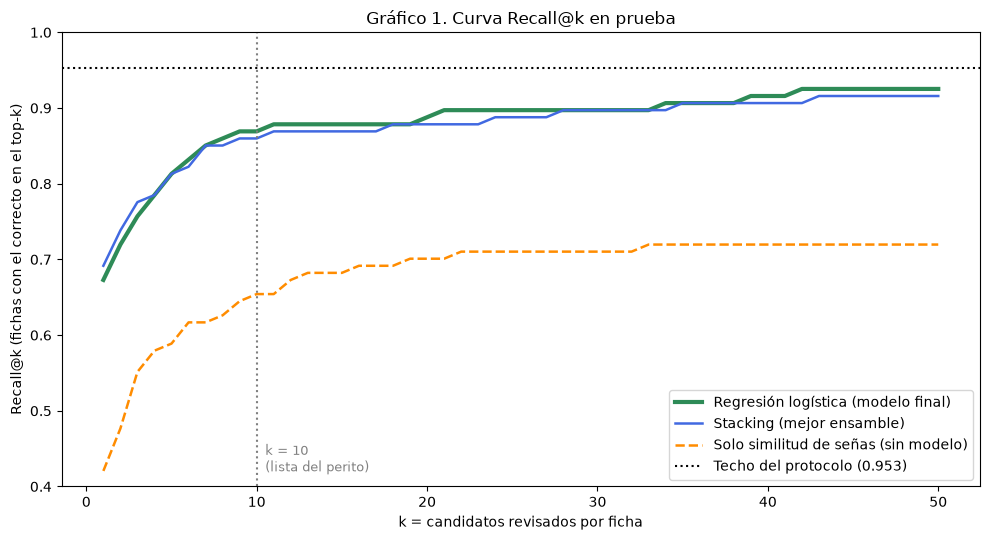

Modelo final: {'Recall@1': np.float64(0.673), 'Recall@5': np.float64(0.813), 'Recall@10': np.float64(0.869), 'Recall@20': np.float64(0.888), 'Recall@50': np.float64(0.925)}
Candidatos promedio por ficha tras el blocking: 630
Fichas fuera del top-50 (o eliminadas por el blocking): 8 de 107


In [14]:
import matplotlib.pyplot as plt

ks = np.arange(1, 51)
r_final = RANGOS['Regresión logística']
curvas = {'Regresión logística (modelo final)': (r_final, dict(lw=3, color='seagreen')),
          'Stacking (mejor ensamble)': (RANGOS['Stacking'], dict(lw=1.8, color='royalblue')),
          'Solo similitud de señas (sin modelo)': (rangos(P_test, P_test['sim_senas'].values), dict(lw=1.8, ls='--', color='darkorange'))}

fig, ax = plt.subplots(figsize=(10, 5.5))
for nombre, (r, estilo) in curvas.items():
    ax.plot(ks, [np.mean(r <= k) for k in ks], label=nombre, **estilo)
ax.axhline(techo, ls=':', color='black', label=f'Techo del protocolo ({techo:.3f})')
ax.axvline(10, ls=':', color='gray'); ax.text(10.5, 0.42, 'k = 10\n(lista del perito)', color='gray', fontsize=9)
ax.set_xlabel('k = candidatos revisados por ficha'); ax.set_ylabel('Recall@k (fichas con el correcto en el top-k)')
ax.set_title('Gráfico 1. Curva Recall@k en prueba'); ax.set_ylim(0.4, 1.0); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

rk = {k: np.mean(r_final <= k) for k in (1, 5, 10, 20, 50)}
print("Modelo final:", {f'Recall@{k}': round(v, 3) for k, v in rk.items()})
print(f"Candidatos promedio por ficha tras el blocking: {len(P_test) / len(Q_test):.0f}")
print(f"Fichas fuera del top-50 (o eliminadas por el blocking): {np.sum(r_final > 50)} de {len(r_final)}")

**Interpretación del Gráfico 1.** La regresión logística coloca el expediente correcto en primer lugar en 67.3 % de
las fichas de prueba y dentro de los 10 primeros en 86.9 %, frente a ~65 % si los candidatos se ordenan solo por
similitud de señas: combinar las 10 pistas recupera unas 23 fichas adicionales de 107. La curva crece rápido hasta
k = 10 y luego casi se aplana (88.8 % en k = 20 y ~92 % en k = 50): ampliar la lista del perito de 10 a 50
candidatos solo rescata unas 6 fichas, porque cuando el modelo falla el correcto suele quedar muy abajo. Eso indica
que los fallos se deben a fichas con poca información, no a un mal ordenamiento. El stacking supera a la logística
solo en las primeras 3–4 posiciones y por márgenes mínimos; desde k = 5 ambas curvas coinciden. La similitud de
señas sola se estanca en ~0.72 porque no puede encontrar a quien no tiene señas registradas. Ninguna curva alcanza el
techo del protocolo (0.953), fijado por el blocking.

**Implicación operativa:** una lista corta de 10 candidatos por ficha captura casi todo el valor del modelo;
alargarla aumenta mucho la carga pericial y aporta poco.

## Gráfico 2: curva Precisión-Recall

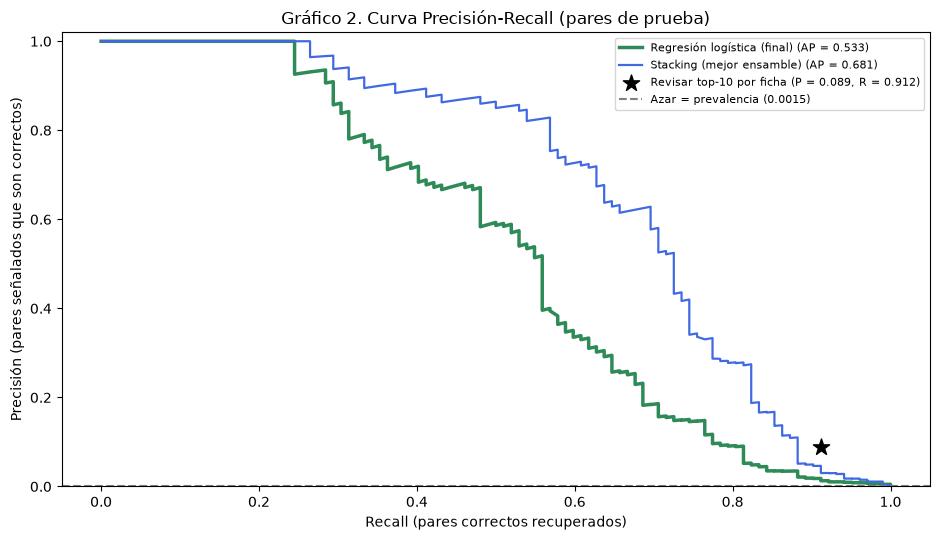

AP logística = 0.533 (352 veces el azar)
Punto de operación top-10: precisión = 0.089 (1 de cada 11 candidatos revisados es el correcto), recall = 0.912


In [16]:
from sklearn.metrics import precision_recall_curve, average_precision_score

s_final = SCORES['Regresión logística']
top10 = (pd.Series(s_final, index=P_test.index).groupby(P_test['QUERY_ID']).rank(method='max', ascending=False) <= 10).values
prev = P_test['y'].mean()

fig, ax = plt.subplots(figsize=(9.5, 5.5))
for nombre, s, estilo in [('Regresión logística (final)', s_final, dict(lw=2.5, color='seagreen')),
                          ('Stacking (mejor ensamble)', SCORES['Stacking'], dict(lw=1.6, color='royalblue'))]:
    p, r, _ = precision_recall_curve(P_test['y'], s)
    ax.plot(r, p, label=f"{nombre} (AP = {average_precision_score(P_test['y'], s):.3f})", **estilo)
op_r, op_p = top10[P_test['y'].values == 1].mean(), P_test['y'].values[top10].mean()
ax.scatter(op_r, op_p, s=150, marker='*', color='black', zorder=5, label=f'Revisar top-10 por ficha (P = {op_p:.3f}, R = {op_r:.3f})')
ax.axhline(prev, ls='--', color='gray', label=f'Azar = prevalencia ({prev:.4f})')
ax.set_xlabel('Recall (pares correctos recuperados)'); ax.set_ylabel('Precisión (pares señalados que son correctos)')
ax.set_title('Gráfico 2. Curva Precisión-Recall (pares de prueba)'); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

print(f"AP logística = {average_precision_score(P_test['y'], s_final):.3f} ({average_precision_score(P_test['y'], s_final) / prev:.0f} veces el azar)")
print(f"Punto de operación top-10: precisión = {op_p:.3f} (1 de cada {1 / op_p:.0f} candidatos revisados es el correcto), recall = {op_r:.3f}")

**Interpretación del Gráfico 2.** Con una prevalencia de 0.15 %, la regresión logística alcanza una precisión
promedio (AP) de 0.533, unas 355 veces la del azar. En el punto de operación real —revisar los 10 primeros
candidatos de cada ficha— la precisión es 0.089 (uno de cada ~11 candidatos revisados es el correcto) y el recall a
nivel par es 0.912. Ese punto queda por encima de ambas curvas: ordenar los candidatos dentro de cada ficha rinde
más que aplicar un umbral único a todos los pares, porque el score de un par solo es comparable con el de los demás
candidatos de su misma ficha.

A nivel global, el stacking supera a la logística (AP 0.681 vs. 0.533): sus scores son más comparables entre fichas
distintas. Esto no cambia la elección para el uso previsto (una lista de candidatos por ficha, donde ambos empatan en
Recall@10), pero sí identifica un escenario en que el ensamble aportaría valor: una bandeja de alertas que priorice
cruces entre todas las fichas abiertas. En ese caso convendría reevaluar el stacking o calibrar la logística.

## Gráfico 3: matriz de confusión operativa

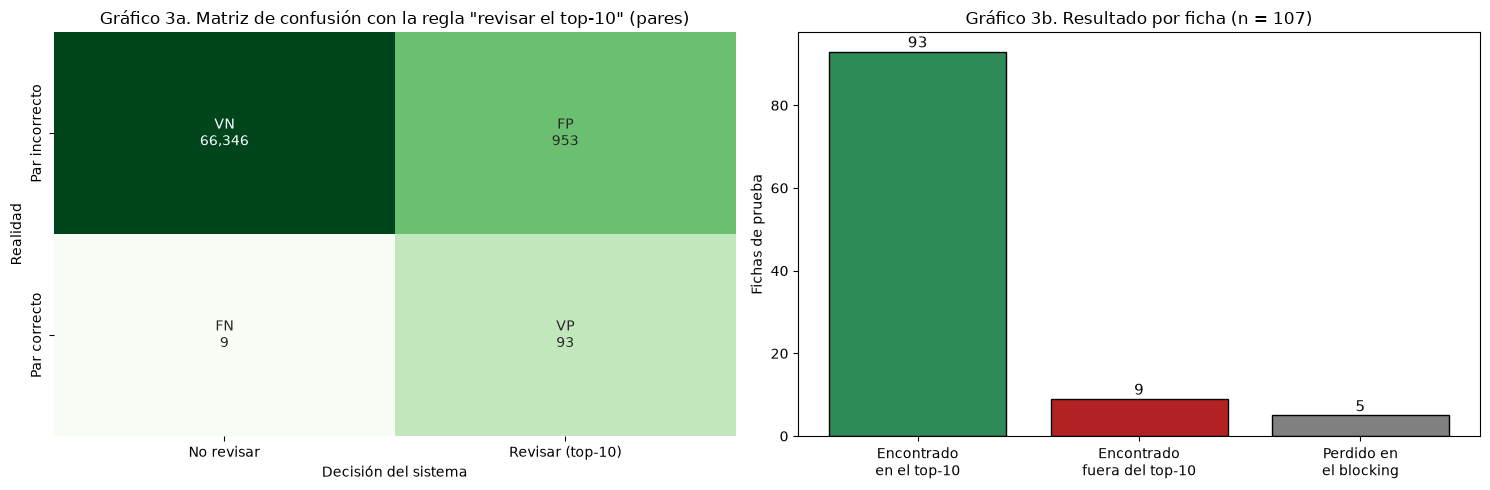

Pares enviados a revisión: 1,046 para 107 fichas | correctos: 93 | incorrectos que revisa el perito: 953
Pares correctos que quedan fuera de la lista (FN): 9 | descartados automáticamente: 66,346 de 67,299 (98.6%)
Fichas: 93 encontradas en top-10, 9 más abajo, 5 perdidas por el blocking


In [19]:
from sklearn.metrics import confusion_matrix
from matplotlib.colors import LogNorm
import seaborn as sns

cm = confusion_matrix(P_test['y'], top10.astype(int))
tn, fp, fn, tp = cm.ravel()
etiquetas = np.array([[f"VN\n{tn:,}", f"FP\n{fp:,}"], [f"FN\n{fn:,}", f"VP\n{tp:,}"]])

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=etiquetas, fmt='', cmap='Greens', norm=LogNorm(), cbar=False, ax=ax[0],
            xticklabels=['No revisar', 'Revisar (top-10)'], yticklabels=['Par incorrecto', 'Par correcto'])
ax[0].set_xlabel('Decisión del sistema'); ax[0].set_ylabel('Realidad')
ax[0].set_title('Gráfico 3a. Matriz de confusión con la regla "revisar el top-10" (pares)')

estado = np.where(r_final <= 10, 'Encontrado\nen el top-10', np.where(np.isfinite(r_final), 'Encontrado\nfuera del top-10', 'Perdido en\nel blocking'))
conteo = pd.Series(estado).value_counts().reindex(['Encontrado\nen el top-10', 'Encontrado\nfuera del top-10', 'Perdido en\nel blocking']).fillna(0)
ax[1].bar(conteo.index, conteo.values, color=['seagreen', 'firebrick', 'gray'], edgecolor='black')
for i, v in enumerate(conteo.values):
    ax[1].text(i, v + 1, f'{int(v)}', ha='center', fontsize=11)
ax[1].set_ylabel('Fichas de prueba'); ax[1].set_title(f'Gráfico 3b. Resultado por ficha (n = {len(r_final)})')
plt.tight_layout(); plt.show()

print(f"Pares enviados a revisión: {tp + fp:,} para {len(r_final)} fichas | correctos: {tp} | incorrectos que revisa el perito: {fp:,}")
print(f"Pares correctos que quedan fuera de la lista (FN): {fn} | descartados automáticamente: {tn:,} de {tn + fp:,} ({tn / (tn + fp):.1%})")
print(f"Fichas: {int(conteo.iloc[0])} encontradas en top-10, {int(conteo.iloc[1])} más abajo, {int(conteo.iloc[2])} perdidas por el blocking")

**Interpretación del Gráfico 3.** Con la regla operativa "revisar los 10 primeros candidatos de cada ficha", el
sistema envía a revisión 1,046 pares para las 107 fichas de prueba, de los cuales 93 son la coincidencia correcta
(VP) y 953 son candidatos incorrectos que el perito descarta (FP). Sin el modelo, habría que revisar los 67,401 pares
que deja el blocking: la carga se reduce unas 64 veces y el 98.6 % de los candidatos incorrectos se descarta
automáticamente. El costo es una precisión operativa de ~9 %: uno de cada 11 candidatos revisados es el correcto.

A nivel ficha (3b), 93 de 107 (86.9 %) encuentran su expediente en la lista. De las 14 que no, 9 lo tienen más abajo
(FN del modelo) y 5 lo perdieron en el blocking, antes de cualquier modelo. Los falsos negativos son el error que
importa —cada uno es una persona cuyo expediente no se revisaría— y más de un tercio proviene del blocking, no del
algoritmo: ampliar la ventana de edad reduciría esos casos a cambio de más candidatos por ficha.

## Gráfico 4: importancia de las pistas

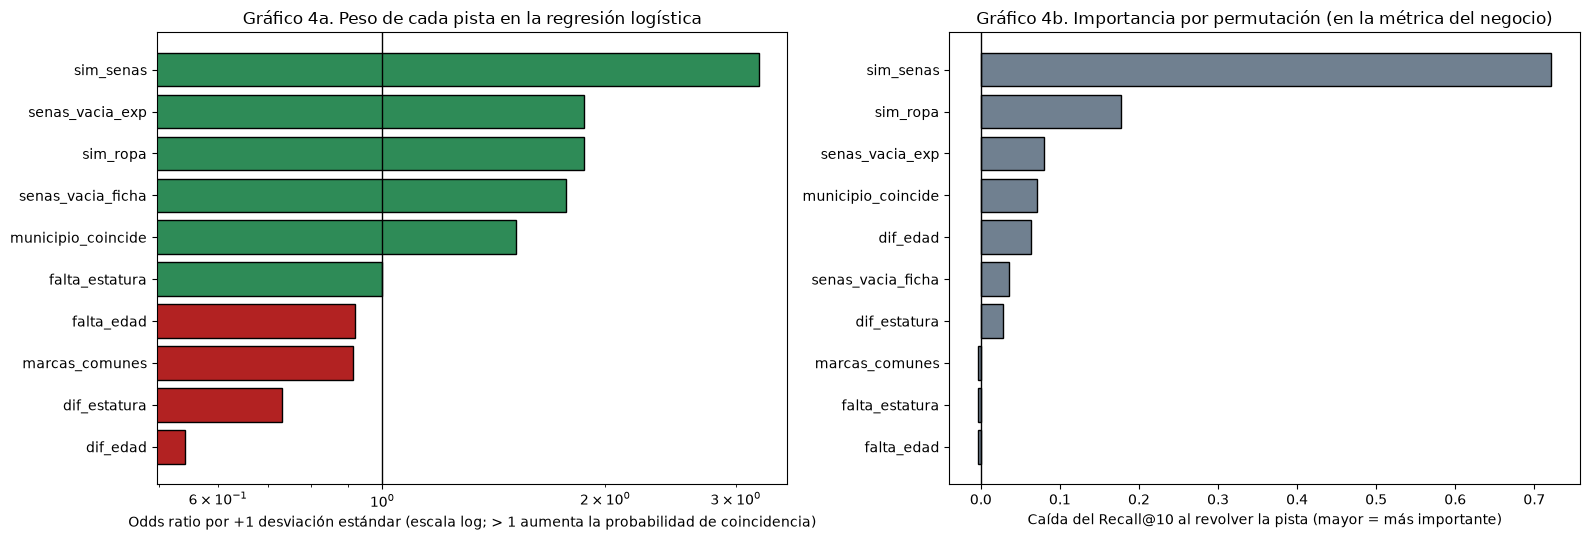

Odds ratios: {'sim_senas': 3.22, 'senas_vacia_exp': 1.87, 'sim_ropa': 1.87, 'senas_vacia_ficha': 1.77, 'municipio_coincide': 1.51, 'falta_estatura': 1.0, 'falta_edad': 0.92, 'marcas_comunes': 0.91, 'dif_estatura': 0.73, 'dif_edad': 0.54}
Caída de Recall@10 al revolver: {'sim_senas': 0.721, 'sim_ropa': 0.178, 'senas_vacia_exp': 0.08, 'municipio_coincide': 0.071, 'dif_edad': 0.064, 'senas_vacia_ficha': 0.036, 'dif_estatura': 0.028, 'falta_edad': -0.004, 'falta_estatura': -0.004, 'marcas_comunes': -0.004}


In [20]:
lr_final = MODELOS_A4['Regresión logística']
coef = pd.Series(lr_final[-1].coef_[0], index=FEATS_SEL)
odds = np.exp(coef).sort_values()

# Importancia por permutación medida en Recall@10 (5 repeticiones por pista)
rng = np.random.default_rng(SEED)
base_r10 = np.mean(r_final <= 10)
caida = {}
for f in FEATS_SEL:
    difs = []
    for _ in range(5):
        Xp = X_te.copy(); Xp[f] = rng.permutation(Xp[f].values)
        difs.append(base_r10 - np.mean(rangos(P_test, puntuar(lr_final, Xp)) <= 10))
    caida[f] = np.mean(difs)
caida = pd.Series(caida).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].barh(odds.index, odds.values, color=['seagreen' if v > 1 else 'firebrick' for v in odds.values], edgecolor='black')
ax[0].axvline(1, color='black', lw=1); ax[0].set_xscale('log')
ax[0].set_xlabel('Odds ratio por +1 desviación estándar (escala log; > 1 aumenta la probabilidad de coincidencia)')
ax[0].set_title('Gráfico 4a. Peso de cada pista en la regresión logística')
ax[1].barh(caida.index, caida.values, color='slategray', edgecolor='black')
ax[1].axvline(0, color='black', lw=1)
ax[1].set_xlabel('Caída del Recall@10 al revolver la pista (mayor = más importante)')
ax[1].set_title('Gráfico 4b. Importancia por permutación (en la métrica del negocio)')
plt.tight_layout(); plt.show()

print("Odds ratios:", odds.sort_values(ascending=False).round(2).to_dict())
print("Caída de Recall@10 al revolver:", caida.sort_values(ascending=False).round(3).to_dict())

**Interpretación del Gráfico 4.** La similitud de señas particulares es la pista dominante: su odds ratio es ≈ 3.2
por desviación estándar y, al revolverla, el Recall@10 cae 0.72 (de 0.87 a ~0.15). Le siguen la similitud de ropa
(OR ≈ 1.9; caída de 0.18), la coincidencia de municipio y la diferencia de edad. La edad tiene el efecto individual
más fuerte en contra (OR ≈ 0.55), pero aporta poco al Recall@10 (~0.07) porque el blocking ya descartó a los
candidatos con más de 15 años de diferencia.

Los indicadores de señas vacías tienen odds ratio > 1 por diseño: cuando un lado no registra señas, la similitud vale
0, y el indicador evita que esa ausencia se lea como evidencia en contra. `marcas_comunes` resulta redundante
(correlación 0.7 con `sim_senas`; importancia por permutación ≈ 0) y su coeficiente ligeramente negativo es efecto
de esa colinealidad, no una relación real. Los faltantes de edad y estatura casi no influyen.

**Implicación para la Fiscalía:** la descripción de señas particulares es la información más valiosa del expediente.
Registrarla siempre, y de forma estructurada (tipo, región, lado, motivo), es la mejora con mayor impacto esperado.

## Gráfico 5: análisis de fallos por tipo de ficha (el último)

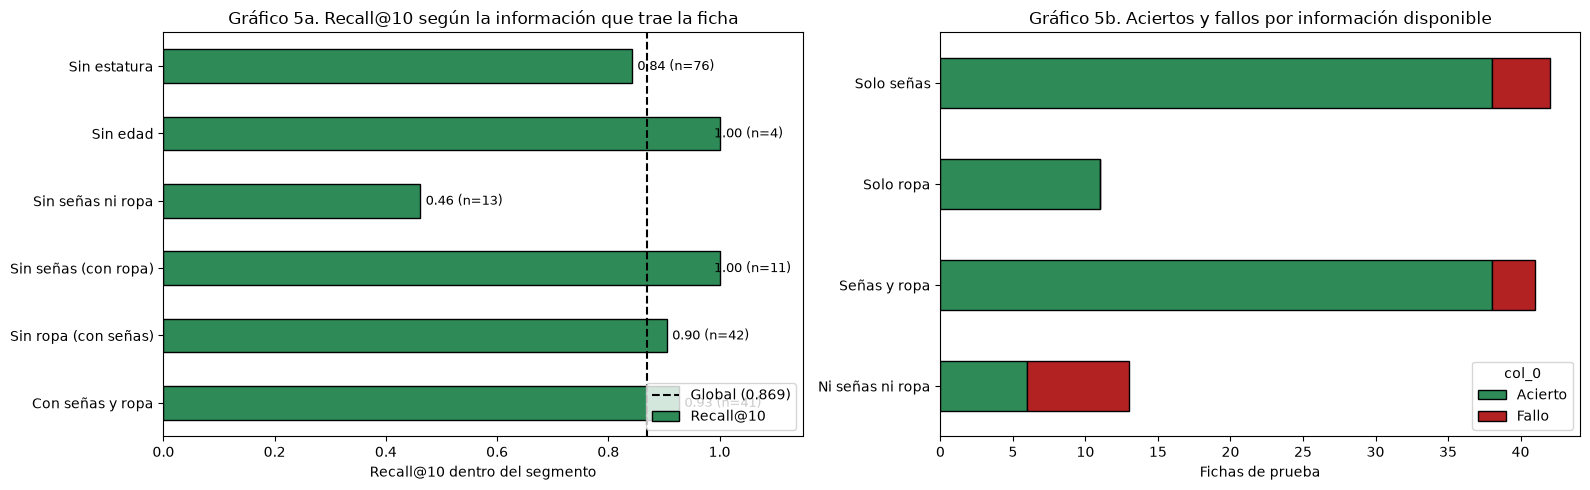

,Fichas,Recall@10,Fallos
Con señas y ropa,41,0.926829,3
Sin ropa (con señas),42,0.904762,4
Sin señas (con ropa),11,1.000000,0
Sin señas ni ropa,13,0.461538,7
Sin edad,4,1.000000,0
Sin estatura,76,0.842105,12


Fallos totales: 14 | de ellos, sin señas: 7 (50%) frente a 22% de fichas sin señas en total


In [21]:
qids = P_test['QUERY_ID'].unique()                         # mismo orden que r_final
Qf = Q_test.set_index('QUERY_ID').loc[qids]
fallo = r_final > 10
segmentos = {'Con señas y ropa': Qf.SENAS.ne('') & Qf.ROPA.ne(''),
             'Sin ropa (con señas)': Qf.SENAS.ne('') & Qf.ROPA.eq(''),
             'Sin señas (con ropa)': Qf.SENAS.eq('') & Qf.ROPA.ne(''),
             'Sin señas ni ropa': Qf.SENAS.eq('') & Qf.ROPA.eq(''),
             'Sin edad': Qf.EDAD.isna(), 'Sin estatura': Qf.ESTATURA.isna()}
seg = pd.DataFrame({'Fichas': {k: int(v.sum()) for k, v in segmentos.items()},
                    'Recall@10': {k: np.mean(~fallo[v.values]) if v.sum() else np.nan for k, v in segmentos.items()},
                    'Fallos': {k: int(fallo[v.values].sum()) for k, v in segmentos.items()}})

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
seg['Recall@10'].plot(kind='barh', ax=ax[0], color='seagreen', edgecolor='black')
for i, (r10, n) in enumerate(zip(seg['Recall@10'], seg['Fichas'])):
    ax[0].text(min(r10, 0.98) + 0.01 if pd.notna(r10) else 0.01, i, f'{r10:.2f} (n={n})' if pd.notna(r10) else 'n=0', va='center', fontsize=9)
ax[0].axvline(np.mean(~fallo), ls='--', color='black', label=f'Global ({np.mean(~fallo):.3f})')
ax[0].set_xlim(0, 1.15); ax[0].set_xlabel('Recall@10 dentro del segmento'); ax[0].legend(loc='lower right')
ax[0].set_title('Gráfico 5a. Recall@10 según la información que trae la ficha')

info = np.where(Qf.SENAS.ne('') & Qf.ROPA.ne(''), 'Señas y ropa', np.where(Qf.SENAS.ne(''), 'Solo señas',
                np.where(Qf.ROPA.ne(''), 'Solo ropa', 'Ni señas ni ropa')))
comp = pd.crosstab(info, np.where(fallo, 'Fallo', 'Acierto'))
comp.plot(kind='barh', stacked=True, ax=ax[1], color={'Acierto': 'seagreen', 'Fallo': 'firebrick'}, edgecolor='black')
ax[1].set_xlabel('Fichas de prueba'); ax[1].set_ylabel(''); ax[1].set_title('Gráfico 5b. Aciertos y fallos por información disponible')
plt.tight_layout(); plt.show()

display(seg)
print(f"Fallos totales: {fallo.sum()} | de ellos, sin señas: {int((Qf.SENAS.eq('').values & fallo).sum())} "
      f"({(Qf.SENAS.eq('').values & fallo).sum() / fallo.sum():.0%}) frente a {Qf.SENAS.eq('').mean():.0%} de fichas sin señas en total")

**Interpretación del Gráfico 5.** Los fallos no son aleatorios: se concentran donde la ficha no trae información
comparable. Las 13 fichas sin señas ni ropa (12 % del total) tienen Recall@10 = 0.46 y acumulan 7 de los 14 fallos
(la mitad). En cambio, cuando la ficha trae señas, ropa o ambas, el Recall@10 está entre 0.90 y 1.00. Sin texto que
comparar, el modelo solo dispone de edad, estatura y municipio, que no individualizan a una persona: ningún
algoritmo puede recuperar información que la ficha no contiene. Los segmentos "solo ropa" (n = 11) y "sin edad"
(n = 4) tienen muy pocas fichas para extraer conclusiones; la ausencia de estatura (n = 76) apenas afecta el
desempeño (0.84), en línea con su baja importancia en el Gráfico 4.

**Implicación para la Fiscalía:** la prioridad no es un algoritmo más complejo, sino garantizar que fichas y
expedientes registren señas particulares y vestimenta. Es la palanca con mayor impacto esperado en la identificación.

# Conclusiones

**1. El cotejo es un sistema, no un modelo.** Encontrar el expediente de una persona desaparecida combina varias
técnicas en cadena: reglas determinísticas (blocking por sexo y edad), similitud léxica de textos (TF-IDF de
n-gramas de caracteres sobre señas y ropa), un modelo que pondera esas pistas y el perito que confirma. El modelo
sugiere; el perito decide.

**2. Se construyeron cuatro ensambles y ninguno supera al mejor modelo individual.** Dos homogéneos (Random Forest
y Gradient Boosting, con búsqueda de hiperparámetros por validación cruzada agrupada por ficha) y dos heterogéneos
(votación ponderada y stacking sobre los tres mejores modelos del Avance 4). En Recall@10 todos empatan
estadísticamente con la regresión logística (bootstrap pareado, B = 2,000: todos los intervalos de la diferencia
cruzan el cero) y en valor puntual quedan entre 1 y 3 fichas por debajo (0.841–0.860 vs. 0.869).

**3. Con pocos casos positivos, gana la simplicidad.** En las cinco búsquedas de hiperparámetros la configuración
ganadora fue la más regularizada. Los ensambles de árboles resultaron además muy sensibles a sus hiperparámetros
(Random Forest 0.766–0.903; Gradient Boosting 0.617–0.875 en validación cruzada). La ventaja de la votación en
validación (una ficha) desapareció en prueba, y sus pesos no fueron estables.

**4. Los modelos se equivocan en las mismas fichas.** La logística y el MLP coinciden en 245 de 248 fichas de
entrenamiento; ninguna combinación de ellos podía recuperar más de 2 fichas (oráculo 0.919 vs. 0.911). Esto explica
por qué los ensambles heterogéneos no mejoran la métrica principal.

**5. Modelo final: regresión logística.** Recall@10 = 0.869 [0.804, 0.925], Recall@1 = 0.673, MRR = 0.732.
Ante el empate estadístico se elige por los criterios del proceso pericial: es el mejor en el error más costoso
(falso negativo), entrena en 0.13 s (400 veces más rápido que el stacking), cada pista tiene un peso explicable al
perito y al Ministerio Público, y puede ejecutarse como una expresión SQL en el sistema real. La elección depende
del caso de uso: para una bandeja de alertas que priorice cruces entre todas las fichas (umbral global), el stacking
separa mejor (AP 0.681 vs. 0.533) y convendría reevaluarlo.

**6. Impacto operativo.** Revisando 10 candidatos por ficha, el perito encuentra el expediente correcto en 93 de
107 fichas y revisa 1,046 pares en lugar de 67,401 (64 veces menos); el 98.6 % de los candidatos incorrectos se
descarta automáticamente.

**7. El límite está en la información, no en el algoritmo.** Las señas particulares son la pista dominante (sin
ellas el Recall@10 cae de 0.87 a ~0.15) y la mitad de los fallos corresponde al 12 % de fichas sin señas ni ropa
(Recall@10 = 0.46). Otros 5 fallos se deben al blocking, no al modelo. Las mejoras con mayor impacto son de
captura y representación: registrar siempre señas y vestimenta de forma estructurada, y usar representaciones
semánticas (embeddings) que reconozcan sinónimos.

**8. Limitaciones.** Los resultados provienen de un registro sintético calibrado con agregados del real y de
pseudo-fichas cuyo ruido definió el equipo; el Recall@10 es un techo optimista. Con 107 fichas de prueba,
diferencias de 1–2 fichas no son distinguibles estadísticamente.

**9. Implicaciones para el sistema real.** Cada componente tiene equivalente en una base de datos con capacidades
vectoriales: blocking con `WHERE`, similitud de trigramas con `pg_trgm`, embeddings con `pgvector` y el modelo final
como suma ponderada en SQL. Combinar modelos sobre las mismas pistas no aportó; combinar fuentes de información
distintas (léxica, vectorial y reglas) es la hipótesis a probar con datos reales. Con cotejos confirmados por la
Fiscalía, el mismo protocolo sustituye las pseudo-fichas por casos reales y produce la cifra de desempeño verdadera.

## Declaración de uso de inteligencia artificial

**Herramienta:** Claude (Anthropic), en claude.ai, como asistente de trabajo. Se usó durante toda la actividad en
una conversación guiada paso a paso.

### Cómo se trabajó

| Etapa | Qué hizo la IA | Qué hizo el equipo |
|---|---|---|
| Lectura del contexto | Revisó el notebook del Avance 4 en el repositorio público del equipo para reutilizar la misma preparación, métricas y configuraciones | Proporcionó el enlace, la rúbrica y las instrucciones de la actividad |
| Datos | Escribió el generador del registro sintético (`Datos/generar_registro_sintetico.py`), calibrado solo con agregados ya publicados en los Avances 3 y 4 | Decidió trabajar con datos sintéticos y pseudo-fichas; generó el archivo en su equipo |
| Diseño del experimento | Propuso el plan por pasos (modelos de referencia, ensambles homogéneos y heterogéneos, tabla con bootstrap, gráficos) y su relación con la búsqueda híbrida del sistema real | Aprobó el plan; pidió avanzar celda por celda y con explicación de cada concepto |
| Código | Redactó cada celda (preparación, métricas, modelos, búsquedas de hiperparámetros, ensambles, bootstrap y gráficos) | Copió, ejecutó y validó cada celda en su ambiente; reportó errores y salidas |
| Explicación | Explicó los conceptos (pseudo-fichas, vector de comparación, TF-IDF, blocking, ensambles, predicciones fuera de pliegue, bootstrap) | Cuestionó los pasos que no le parecían justificados; por ejemplo, señaló que la ganancia de la votación podía ser azar ("un volado"), lo que se confirmó en prueba |
| Interpretación | Propuso la lectura de cada tabla y gráfico **a partir de las salidas que el equipo le compartió**, y redactó los borradores de interpretación y conclusiones | Revisó y ajustó los textos; decidió el modelo final con los criterios del proceso pericial |

### Lo que la IA no hizo

- **Ninguna cifra de este notebook proviene de la IA.** Todos los resultados se generaron al ejecutar el notebook en
  el equipo del autor; la IA solo vio las salidas que se le compartieron.
- **La IA no tuvo acceso a datos reales.** No se compartió con ella el registro del SEMEFO ni fichas reales; todo el
  trabajo se hizo sobre el registro sintético.
- La IA no modificó resultados ni eligió el modelo final de forma autónoma.

### Decisión metodológica registrada

**Decisión 28 — Retomar la simulación para el Avance 5.**
- *Decisión:* evaluar los ensambles con pseudo-fichas sobre un registro sintético con la misma estructura y perfil
  agregado que el real.
- *Justificación:* la rúbrica exige modelos supervisados (stacking, métricas con verdad conocida) y no existen pares
  ficha–expediente confirmados; el registro sintético permite desarrollar sin exponer datos sensibles.
- *Alternativa descartada:* ensambles no supervisados sobre las tablas reales de Databricks (fusión de rankings
  medida con cobertura). Se descartó porque no permite calcular Recall@k ni cumplir los criterios de la rúbrica.
  Reabre la Decisión 24 por decisión del autor.
- *Participación de la IA:* inventarió las tablas de Databricks, explicó las dos alternativas y escribió el generador
  del registro sintético; la decisión fue del autor.

### Alcance de los resultados

Las cifras corresponden a **datos sintéticos** y a pseudo-fichas cuyo ruido definió el equipo. Son un techo optimista
del desempeño y no deben citarse como resultados sobre el registro real del SEMEFO.

## Referencias

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Christen, P. (2012). *Data matching: Concepts and techniques for record linkage, entity resolution, and duplicate detection*. Springer. https://doi.org/10.1007/978-3-642-31164-2

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.

Fellegi, I. P., & Sunter, A. B. (1969). A theory for record linkage. *Journal of the American Statistical Association, 64*(328), 1183–1210. https://doi.org/10.1080/01621459.1969.10501049

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to information retrieval*. Cambridge University Press.

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Studer, S., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413. https://doi.org/10.3390/make3020020

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259. https://doi.org/10.1016/S0893-6080(05)80023-1